Get gene annotations with RNA-seq supported introns for Entodinium caudatum

* We are interested in intron lengths and relative position (in gene body)
* However, intron annotations from gene predictions may reflect model biases 
* Therefore, we first call introns from RNAseq mapping and filter for those with >5 fold coverage
* We then identify gene annotations with introns in exactly those coordinates, to get a subset of genes with empirically supported intron predictions for our intron relative position metrics
* For predicted gene with RNAseq support, the boundaries of the predicted genes appear to correspond closely to RNAseq coverage, on visual inspection of mapping

In [156]:
import gffutils
import pysam

import matplotlib.pyplot as plt

from collections import Counter

## Entodinium caudatum

Reannotation uses standard genetic code: Codetta predicted standard code for this genome.

Visual inspection of the new gene prediction vs. old prediction by the original authors: Predictions largely overlap; where RNAseq mappings are available the predicted introns largely overlap with observed in the RNAseq reads. BRAKER sometimes predicts 'genes' that span scaffold gaps (runs of `N`s), which contributes the spurious gene predictions.

Old prediction has a sharp intron length cutoff around 30 bp that is likely an arbitrary cutoff value. Both predictions have many introns that are at the 3' end of genes, which looks like a prediction artefact, although the proportion of these is somewhat smaller in the new prediction.

The longest contig `Ento_MGS_1` has no RNAseq reads mapped but lots of predicted genes; Blast of selected regions and `mmseqs taxonomy` confirm that this contig is a methanogen sequence. There are other likely contaminant sequences too, and spurious genes predicted here may contribute to some of the artefacts seen.

In [157]:
annot = "genepred/braker_out/braker.gtf"
# hints = "genepred/ecau2/hintsfile.gff"

ecau_bam = pysam.AlignmentFile("map/SRR8478280.ecau.hisat2.sort.bam", "rb")

ecau_rnaseq_introns = {}
for ctg in ecau_bam.references:
    ecau_rnaseq_introns[ctg] = ecau_bam.find_introns((read for read in ecau_bam.fetch(contig=ctg)))

In [65]:
# we do not disable_infer_genes when importing, despite the warning message,
# because the gene features in the GTF file produced by Braker3 do not have correctly formatted name attributes, so they won't be correctly parsed
# so it is easier to just let gffutils infer the genes from exons and CDSs

db = gffutils.create_db(annot, dbfn="genepred/braker.gffutils.db", force=True, keep_order=True, sort_attribute_values=True)

In [174]:
# Find empirically supported introns directly from RNAseq mapping
min_mult = 5
supported_introns = []
for seqid in ecau_rnaseq_introns:
    for (intron_start, intron_end) in ecau_rnaseq_introns[seqid]:
        mult = ecau_rnaseq_introns[seqid][(intron_start,intron_end)]
        if mult >= min_mult:
            in_pred = [
                j for j in db.region(seqid=seqid, start=intron_start + 1, end=intron_end, completely_within=True) # start+1 because pysam uses 0-based numbering, GFF3 uses 1-based
                if j.source == "AUGUSTUS"
                and j.featuretype == "intron" # some introns overlap with predicted start/stop codons
            ]
            if len(in_pred) == 1:
                supported_introns.append(in_pred[0])

In [177]:
parent_genes = []
for i in supported_introns:
    gene_id = i.attributes.get("gene_id")[0]
    parent_genes.append(db[gene_id])

In [178]:
len(supported_introns)

2234

In [179]:
len(parent_genes)

2234

```
<<< gene.start     intron.start    intron.end    gene.end <<<

<<< cds.start    cds.end intron.start intron.end   cds.start  cds.end <<<
```

In [180]:
# Get relative positions within gene body of introns with empirical support
# Relative positions count only CDS features, ignore any upstream introns
poss = []
for gene, intron in zip(parent_genes, supported_introns):
    if gene.strand == intron.strand:
        #print(gene.start, gene.end, 
        cdss = [i for i in db.children(gene.id) if i.featuretype == "CDS"] # all CDSs for this gene
        if gene.strand == "+":
            before_intron = [cds for cds in cdss if cds.end < intron.start] # CDSs upstream of this intron
        else:
            before_intron = [cds for cds in cdss if cds.start > intron.end] # CDSs upstream of this intron
        cds_len = sum([len(cds) for cds in cdss])
        before_intron_len = sum([len(i) for i in before_intron])
        relpos = before_intron_len / cds_len
        poss.append(relpos)

In [205]:
# Get relative positions within gene body of predicted introns
# Relative positions count only CDS features, ignore any upstream introns
poss_pred = []
for intron in db.features_of_type('intron'): # all predicted
    #for gene, intron in zip(parent_genes, supported_introns):
    if 'gene_id' in intron.attributes:
        gene_id = intron.attributes['gene_id'][0]
        gene = db[gene_id]
        if gene.strand == intron.strand:
            cdss = [i for i in db.children(gene.id, featuretype="CDS")] # all CDSs for this gene
            if gene.strand == "+":
                before_intron = [cds for cds in cdss if cds.end < intron.start] # CDSs upstream of this intron
            else:
                before_intron = [cds for cds in cdss if cds.start > intron.end] # CDSs upstream of this intron
            cds_len = sum([len(cds) for cds in cdss])
            before_intron_len = sum([len(i) for i in before_intron])
            relpos = before_intron_len / cds_len
            poss_pred.append(relpos)

Histogram of relative intron positions for Entodinium caudatum

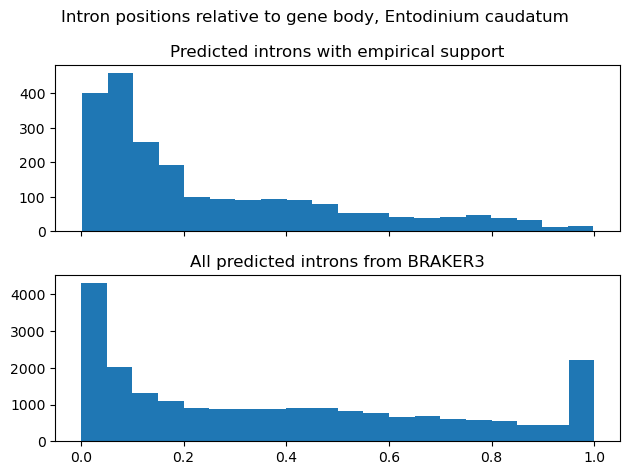

In [232]:
fig, ax = plt.subplots(2,1, sharex=True)
ax[0].hist(poss, bins=20)
ax[0].set_title("Predicted introns with empirical support")
ax[1].hist(poss_pred, bins=20)
ax[1].set_title("All predicted introns from BRAKER3")
fig.suptitle("Intron positions relative to gene body, Entodinium caudatum")
fig.tight_layout()

In [214]:
# Empirically supported introns
len_counts = Counter([len(i) for i in supported_introns])
xx3 = [x for x in len_counts.keys() if x % 3 == 0]
yy3 = [len_counts[x] for x in xx3]
xx_ = [x for x in len_counts.keys() if x % 3 != 0]
yy_ = [len_counts[x] for x in xx_]

# Predicted introns
len_pred_counts = Counter([len(intron) for intron in db.features_of_type('intron')])
lpc_xx3 = [x for x in len_pred_counts.keys() if x%3 == 0]
lpc_xx_ = [x for x in len_pred_counts.keys() if x%3 != 0]
lpc_yy3 = [len_pred_counts[x] for x in lpc_xx3]
lpc_yy_ = [len_pred_counts[x] for x in lpc_xx_]

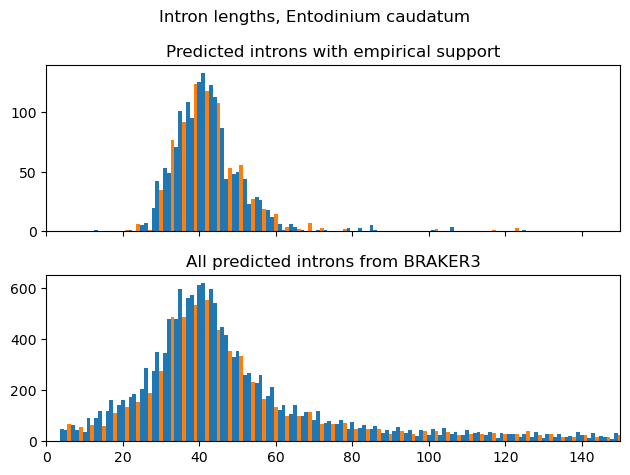

In [221]:
fig, ax = plt.subplots(2,1, sharex=True)

ax[0].bar(x=xx_, height=yy_, width=1)
ax[0].bar(x=xx3, height=yy3, width=1)
ax[0].set_xlim(0,150)
ax[0].set_title("Predicted introns with empirical support")

ax[1].bar(x=lpc_xx_, height=lpc_yy_, width=1)
ax[1].bar(x=lpc_xx3, height=lpc_yy3, width=1)
ax[1].set_title("All predicted introns from BRAKER3")
fig.suptitle("Intron lengths, Entodinium caudatum")
fig.tight_layout()

* Relative position of introns: Strong 5' bias for empirically supported introns, but apparent 3'-positioned introns not observed
* Length distribution of introns with empirical support is narrower than for all predicted introns, suggests that the gene predicter is somewhat over-predicting shorter and longer introns. This is consistent with what we've observed before in other ciliate genome annotations.